Oleksandr Reshetnikov (2409418)


# Introduction

### Skin Lesion Classification on ISIC 2019

Module: CM4126 Computer Vision

GitHub repository: https://github.com/batreller/CM4126-Coursework

Dataset: ISIC 2019 Challenge (25331 images, 8 categories)

Paper: Matsoukas, C. *et al.* (2022) 'What makes transfer learning work for medical images: feature reuse & other factors', *2022 IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. New Orleans (USA), 18-24 June. Piscataway, NJ: IEEE. pp. 9215-9224. Available at: https://doi.org/10.1109/CVPR52688.2022.00901 (Accessed: 13 November 2026).

...



# Research and Data Exploration
...


### Dataset download


The dataset is downloaded from the official ISIC archive using the code below. It includes training and test images with labels and metadata. The code only downloads each file if it isn't already downloaded and extracts ZIP archives (and removes them after extraction to save space). It puts all downloaded data into `data/raw/isic2019` folder.

In [1]:
import zipfile
from datetime import date
from pathlib import Path

import requests
from tqdm import tqdm

DATA_DIR = Path("data/raw/isic2019")
BASE_URL = "https://isic-archive.s3.amazonaws.com/challenges/2019/"
ISIC_FILES = [
    "ISIC_2019_Training_GroundTruth.csv",  # 1 mb
    "ISIC_2019_Training_Metadata.csv",  # 1 mb
    "ISIC_2019_Test_GroundTruth.csv",  # 454 kb
    "ISIC_2019_Test_Metadata.csv",  # 287 kb
    "ISIC_2019_Training_Input.zip",  # 9.1 gb
    "ISIC_2019_Test_Input.zip",  # 3.6 gb
]

# gets a remote file size
def remote_size(url):
    response = requests.head(url, timeout=30)
    response.raise_for_status()
    return int(response.headers["Content-Length"])

# downloads a file
def download_file(url, target):
    part = target.with_name(target.name + ".part")  # so that interrupted download didn't look like it was completed
    with requests.get(url, stream=True, timeout=30) as response:
        response.raise_for_status()
        total = int(response.headers["Content-Length"])
        with open(part, "wb") as out, tqdm(total=total, unit="B", unit_scale=True, desc=target.name) as bar:  # to visually display downloading progress
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                out.write(chunk)
                bar.update(len(chunk))
    part.replace(target)  # rename file at the end


def download_isic2019(data_dir=DATA_DIR, delete_zips=True):
    data_dir.mkdir(parents=True, exist_ok=True)

    for name in ISIC_FILES:
        url = BASE_URL + name
        target = data_dir / name

        # empty marker for zip files, as zip files are removed after extraction
        # this file is used to know whether zip was already downloaded and extracted or wasn't even downloaded yet
        extracted_marker = data_dir / (name + ".extracted")

        if extracted_marker.exists():
            print(f"{name}: already downloaded and extracted")
            continue

        if target.exists() and target.stat().st_size == remote_size(url):
            print(f"{name}: already downloaded")
        else:
            download_file(url, target)

        if name.endswith(".zip"):
            with zipfile.ZipFile(target) as archive:
                for member in tqdm(archive.infolist(), desc=f"Extracting {name}", unit="file"):
                    archive.extract(member, data_dir)
            extracted_marker.touch()  # create empty marker file only after extraction is finished
            if delete_zips:
                target.unlink()  #  remove zip

    stamp = data_dir / "DOWNLOADED_AT.txt"
    if not stamp.exists():
        stamp.write_text(date.today().isoformat())
    print("Dataset downloaded on:", stamp.read_text())

In [2]:
# download datasets
download_isic2019()

ISIC_2019_Training_GroundTruth.csv: already downloaded
ISIC_2019_Training_Metadata.csv: already downloaded
ISIC_2019_Test_GroundTruth.csv: already downloaded
ISIC_2019_Test_Metadata.csv: already downloaded
ISIC_2019_Training_Input.zip: already downloaded and extracted
ISIC_2019_Test_Input.zip: already downloaded and extracted
Dataset downloaded on: 2026-11-14


In [3]:
import pandas as pd

CLASS_NAMES = {
    "MEL": "Melanoma",  # malignant, the most dangerous skin cancer
    "NV": "Melanocytic nevus",  # benign
    "BCC": "Basal cell carcinoma",  # malignant, spreads very rarely
    "AK": "Actinic keratosis",  # pre-cancerous
    "BKL": "Benign keratosis",  # benign
    "DF": "Dermatofibroma",  # benign
    "VASC": "Vascular lesion",  # benign
    "SCC": "Squamous cell carcinoma",  # malignant
}
CLASSES = list(CLASS_NAMES)

# loads labels and metadata into one table with 1 row per image
def load_split(split):
    labels = pd.read_csv(DATA_DIR / f"ISIC_2019_{split}_GroundTruth.csv")
    metadata = pd.read_csv(DATA_DIR / f"ISIC_2019_{split}_Metadata.csv")

    # labels are encoded with one-hot so we convert each row into single class name
    # UNK must be included, otherwise all zero rows will be handled as the first class
    labels["label"] = labels[CLASSES + ["UNK"]].idxmax(axis=1)

    # take only `image` and `label` from `labels` and merge it with `metadata`.
    df = labels[["image", "label"]].merge(metadata, on="image", how="left", validate="one_to_one")
    # add `path` column with full path to the image
    df["path"] = [DATA_DIR / f"ISIC_2019_{split}_Input" / f"{name}.jpg" for name in df["image"]]
    return df

In [4]:
# now let's load both training and test splits
train_df = load_split("Training")
test_df = load_split("Test")

# and see their shapes
print("Train:", train_df.shape, " Test:", test_df.shape)
train_df.head()

Train: (25331, 7)  Test: (8238, 6)


,image,label,age_approx,anatom_site_general,lesion_id,sex,path
0,ISIC_0000000,NV,55.0,anterior torso,NaN,female,data\raw\isic2019\ISIC_2019_Training_Input\ISI...
1,ISIC_0000001,NV,30.0,anterior torso,NaN,female,data\raw\isic2019\ISIC_2019_Training_Input\ISI...
2,ISIC_0000002,MEL,60.0,upper extremity,NaN,female,data\raw\isic2019\ISIC_2019_Training_Input\ISI...
3,ISIC_0000003,NV,30.0,upper extremity,NaN,male,data\raw\isic2019\ISIC_2019_Training_Input\ISI...
4,ISIC_0000004,MEL,80.0,posterior torso,NaN,male,data\raw\isic2019\ISIC_2019_Training_Input\ISI...


### Class distribution

In [5]:
train_counts = train_df["label"].value_counts()
train_counts  # number of training images per class

label
NV      12875
MEL      4522
BCC      3323
BKL      2624
AK        867
SCC       628
VASC      253
DF        239
Name: count, dtype: int64

As we can see here train set does not have any images with UNK (unknown) class

In [6]:
train_percent = (train_counts / len(train_df) * 100).round(1)
train_percent  # share of each class in training set

label
NV      50.8
MEL     17.9
BCC     13.1
BKL     10.4
AK       3.4
SCC      2.5
VASC     1.0
DF       0.9
Name: count, dtype: float64

In [7]:
test_counts_all = test_df["label"].value_counts()
test_counts_all  # number of test images per class

label
NV      2495
UNK     2047
MEL     1327
BCC      975
BKL      660
AK       374
SCC      165
VASC     104
DF        91
Name: count, dtype: int64

We can see that in test set we have 2047 images with UNK (unknown) class, we will need to remove them because our model will only be predicting 8 classes because we do not have any UNK class in train set.

In [8]:
test_percent_all = (test_counts_all / len(test_df) * 100).round(1)
test_percent_all  # share of each class in test set

label
NV      30.3
UNK     24.8
MEL     16.1
BCC     11.8
BKL      8.0
AK       4.5
SCC      2.0
VASC     1.3
DF       1.1
Name: count, dtype: float64

In [9]:
test_known = test_df[test_df["label"] != "UNK"]  # removing UNK class from test dataset

print("Test images before:", len(test_df))
print("UNK images removed:", len(test_df) - len(test_known))
print("Test images after: ", len(test_known))


Test images before: 8238
UNK images removed: 2047
Test images after:  6191


In [10]:
test_counts = test_known["label"].value_counts()
test_counts  # number of test images per class after UNK images were removed

label
NV      2495
MEL     1327
BCC      975
BKL      660
AK       374
SCC      165
VASC     104
DF        91
Name: count, dtype: int64

In [11]:
test_percent = (test_counts / len(test_known) * 100).round(1)
test_percent  # share of each class in test set after UNK images were removed

label
NV      40.3
MEL     21.4
BCC     15.7
BKL     10.7
AK       6.0
SCC      2.7
VASC     1.7
DF       1.5
Name: count, dtype: float64

In [12]:
distribution = pd.DataFrame({
    "Train": train_counts,
    "Train %": train_percent,
    "Test": test_counts,
    "Test %": test_percent,
})
distribution

,Train,Train %,Test,Test %
label,,,,
NV,12875,50.8,2495,40.3
MEL,4522,17.9,1327,21.4
BCC,3323,13.1,975,15.7
BKL,2624,10.4,660,10.7
AK,867,3.4,374,6.0
SCC,628,2.5,165,2.7
VASC,253,1.0,104,1.7
DF,239,0.9,91,1.5


In [13]:
print("Imbalance ratio:", round(train_counts.max() / train_counts.min(), 1))

Imbalance ratio: 53.9


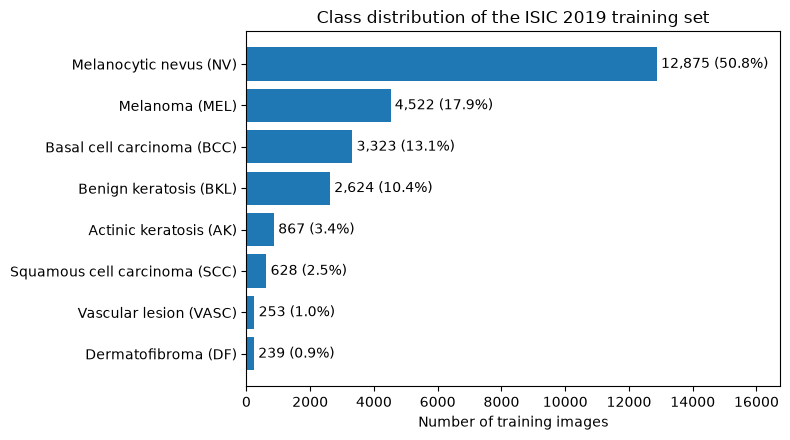

In [14]:
import matplotlib.pyplot as plt

# smallest class at the bottom
counts_sorted = train_counts.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))  # empty image 8 x 4.5

# horizontal bars with full class names
bars = ax.barh([f"{CLASS_NAMES[code]} ({code})" for code in counts_sorted.index], counts_sorted.values)
# on the right of each bar we add count and percent
ax.bar_label(bars, labels=[f"{n:,} ({100 * n / counts_sorted.sum():.1f}%)" for n in counts_sorted.values], padding=3)

ax.set_xlabel("Number of training images")
ax.set_title("Class distribution of the ISIC 2019 training set")
ax.set_xlim(0, counts_sorted.max() * 1.3)
fig.tight_layout()
plt.show()

*Figure 1: Class distribution of the ISIC 2019 training set.*

This dataset has a strong imbalance - 53.9 and NV is in around 51% of images, so a model that always predicts NV will get around 51% accuracy. To avoid that we need to use balanced accuracy and per class recall. Because of the imbalance I will use class weighted cross entropy, this way errors on rare classes will be penalised more.

Also class proportions are different in test set, it contains more MEL (21.4% vs 17.9%), AK (6% vs 3.4%) and less NV (40.3% vs 50.8%). This means that balanced accuracy should be used as the main metric.